# Prevendo Nível de trânsito
- Ultilizando modelos de previsão de séries temporais

Importando bibliotecas necessárias

In [ ]:
!pip install sktime
!pip install pmdarima
!pip install holidays
!pip install -U statsforecast
!pip install darts
import holidays
import pandas as pd
from sktime.datasets import load_forecastingdata
from google.colab import drive
from sktime.utils import plot_series
import numpy as np
import matplotlib.pyplot as plt
from darts.models import NaiveSeasonal, ARIMA, SKLearnModel, RNNModel
from sktime.forecasting.arima import AutoARIMA
from sklearn.linear_model import LinearRegression
from darts.metrics import mse, rmse
from darts import TimeSeries
from sklearn.preprocessing import MinMaxScaler
from sktime.performance_metrics.forecasting import mean_squared_error
from sklearn.compose import ColumnTransformer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.5/151.5 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 10.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.6/354.6 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.4/287.4 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.7/280.7 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 4.4 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Baixando dataset

In [ ]:
name = "traffic_hourly_dataset"

x, y = load_forecastingdata(name=name) # Taxas de ocupação nas rodovias da área da Baía de São Francisco de 2015 a 2016

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: b629ab87-5be4-49c0-83f5-847ad7ed638b)')' thrown while requesting HEAD https://huggingface.co/datasets/sktime/tsf-datasets/resolve/1543ace631117eb8a4df6bfbd01c6a8fdad74c6c/traffic_hourly_dataset/traffic_hourly_dataset.tsf
Retrying in 1s [Retry 1/5].


traffic_hourly_dataset/traffic_hourly_da(…):   0%|          | 0.00/103M [00:00<?, ?B/s]

In [ ]:
print(y)

{'frequency': 'hourly', 'forecast_horizon': None, 'contain_missing_values': False, 'contain_equal_length': True}


In [ ]:
def get_pd_series_by_idx(df: pd.DataFrame, idx: int) -> pd.DataFrame:
    values = np.array(df.iloc[idx]["series_value"])

    t0 = df.index[idx]

    time_index = pd.date_range(
        start=t0,
        periods=len(values),
        freq="h"
    )
    return pd.DataFrame(
        {"valor": values},
        index=time_index
    )

Pegando apenas uma série temporal

In [ ]:
df = pd.DataFrame(x).drop("series_name", axis=1).set_index("start_timestamp")
df.index = pd.to_datetime(df.index)
df.head()

,series_value
start_timestamp,
2015-01-01 00:00:01,"[0.0048, 0.0072, 0.004, 0.0039, 0.0042, 0.004,..."
2015-01-01 00:00:01,"[0.0146, 0.0148, 0.0101, 0.006, 0.0055, 0.0071..."
2015-01-01 00:00:01,"[0.0289, 0.035, 0.0267, 0.0218, 0.0191, 0.0213..."
2015-01-01 00:00:01,"[0.0142, 0.0174, 0.0124, 0.009, 0.0082, 0.0106..."
2015-01-01 00:00:01,"[0.0064, 0.0084, 0.0049, 0.0029, 0.0024, 0.003..."


In [ ]:
sample = get_pd_series_by_idx(df, 430)
print(len(sample))
print(sample.max())
print(sample.min())
sample.head()

17544
valor    0.6595
dtype: float64
valor    0.0
dtype: float64


,valor
2015-01-01 00:00:01,0.0110
2015-01-01 01:00:01,0.0128
2015-01-01 02:00:01,0.0080
2015-01-01 03:00:01,0.0040
2015-01-01 04:00:01,0.0023


**Analisando** **dados**

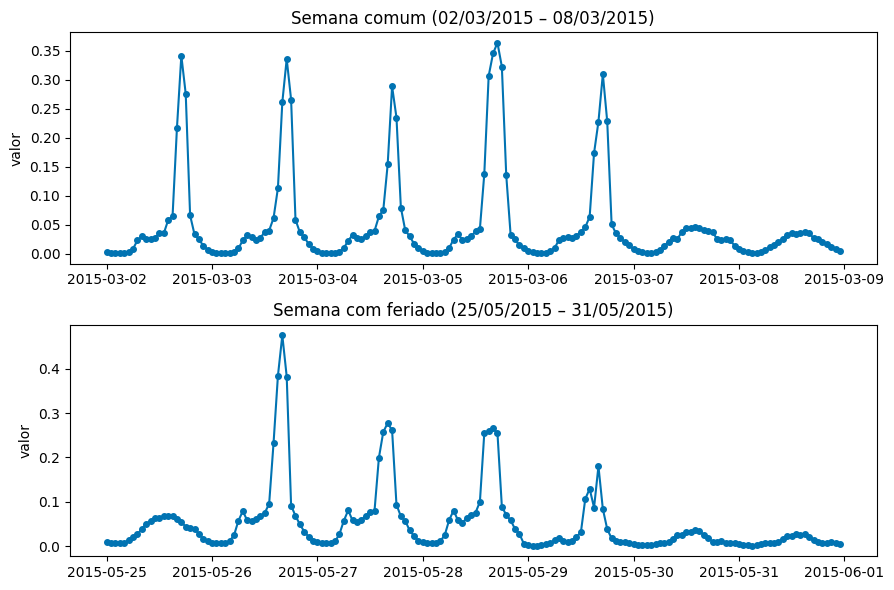

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=False)

plot_series(
    sample.loc[(sample.index > "2015-03-02") & (sample.index < "2015-03-09")],
    ax=axes[0]
)
axes[0].set_title("Semana comum (02/03/2015 – 08/03/2015)")

plot_series(
    sample.loc[(sample.index > "2015-05-25") & (sample.index < "2015-06-01")],
    ax=axes[1]
)
axes[1].set_title("Semana com feriado (25/05/2015 – 31/05/2015)")

plt.tight_layout()
plt.show()

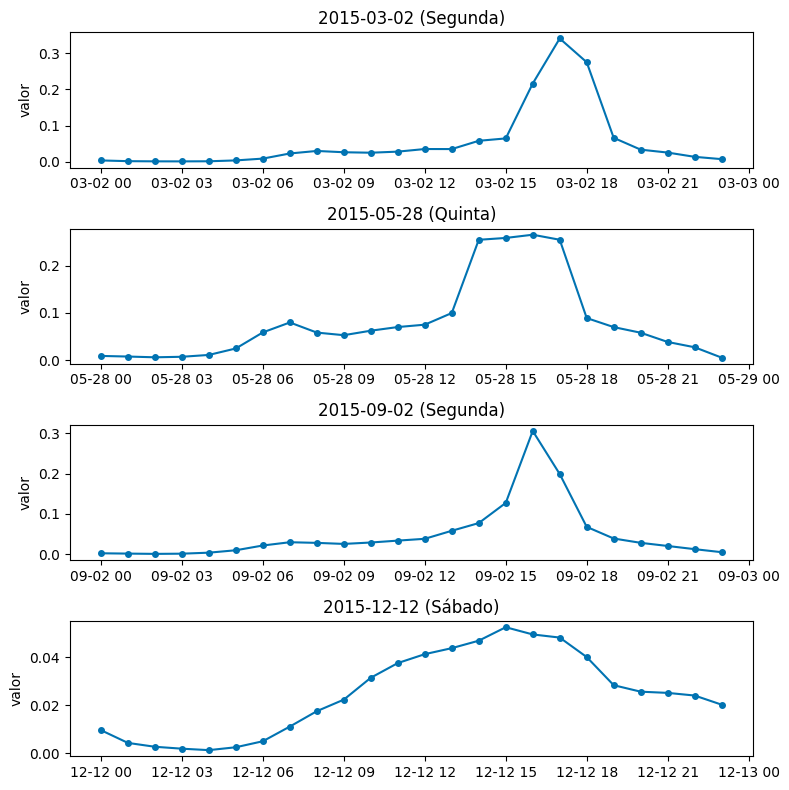

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(8, 8), sharex=False) # melhorar a questão da plotagem: grid, proporção de valores

plot_series(sample.loc["2015-03-02"], ax=axes[0])
axes[0].set_title("2015-03-02 (Segunda)")

plot_series(sample.loc["2015-05-28"], ax=axes[1])
axes[1].set_title("2015-05-28 (Quinta)")

plot_series(sample.loc["2015-09-02"], ax=axes[2])
axes[2].set_title("2015-09-02 (Segunda)")

plot_series(sample.loc["2015-12-12"], ax=axes[3])
axes[3].set_title("2015-12-12 (Sábado)")

plt.tight_layout()
plt.show()

Criando novas colunas para o dataset

In [ ]:
def creat_features(df):
  sample = df.copy()
  us_ca_holidays = holidays.US(state="CA")

  sample["holiday"] = sample.index.isin(us_ca_holidays).astype(int)
  sample["hour"] = sample.index.hour
  sample["month"] = sample.index.month
  sample["dayofweek"] = sample.index.dayofweek

  return sample

FEATURES = ['holiday', 'hour', 'month', 'dayofweek']
TARGET = ['valor']

sample = creat_features(sample)
sample.tail()

,valor,holiday,hour,month,dayofweek
2016-12-31 19:00:01,0.0272,0,19,12,5
2016-12-31 20:00:01,0.0236,0,20,12,5
2016-12-31 21:00:01,0.0241,0,21,12,5
2016-12-31 22:00:01,0.0238,0,22,12,5
2016-12-31 23:00:01,0.0174,0,23,12,5


Dividindo entre treino e teste

In [ ]:
def temporal_train_test_split(df: pd.DataFrame, train_size=0.8):
    n = len(df)

    train_end = int(n * train_size)

    train = df.iloc[:train_end]
    test = df.iloc[train_end:]

    return train, test

In [ ]:
train, test = temporal_train_test_split(sample)

len(train), len(test)

(14035, 3509)

(<Figure size 1600x400 with 1 Axes>, <Axes: ylabel='valor'>)

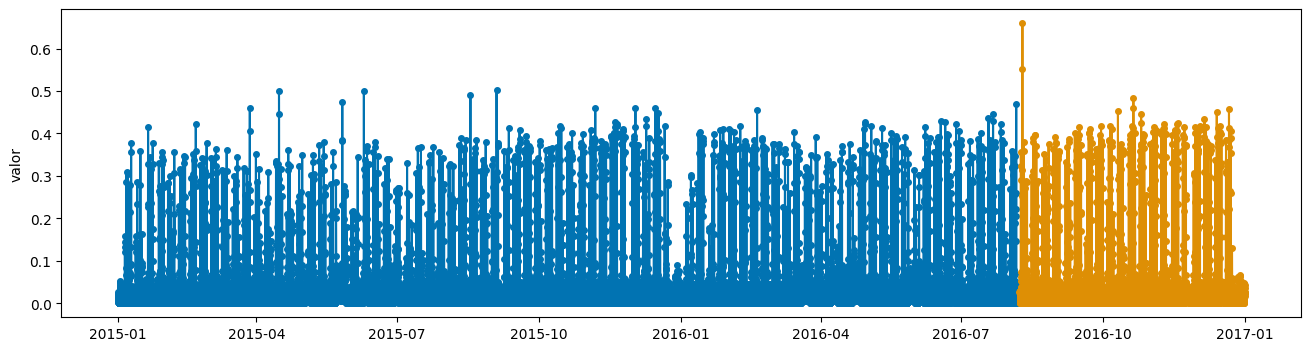

In [ ]:
plot_series(train.valor, test.valor)

Pre-Processamento
- utilizei min max para ficar entre [0,1]

In [ ]:
scaler = MinMaxScaler()  # [0,1]

train.loc[:, ["valor"]] = scaler.fit_transform(train[["valor"]])
test.loc[:, ["valor"]] = scaler.transform(test[["valor"]])

# retirar valores maiores que 1 e substituir por 1

train.loc[train["valor"] > 1, "valor"] = 1
test.loc[test["valor"] > 1, "valor"] = 1

transformar em time series

In [ ]:
y_train_ts = TimeSeries.from_dataframe(
    train,
    value_cols= TARGET
)

x_train_ts = TimeSeries.from_dataframe(
    train,
    value_cols=FEATURES
)

y_test_ts = TimeSeries.from_dataframe(
    test,
    value_cols= TARGET
)

x_test_ts = TimeSeries.from_dataframe(
    test,
    value_cols=FEATURES
)

Modelos
- naive seasonal
- arima
- auto arima
- regressão linear
- rnn

In [ ]:
naive_model = NaiveSeasonal(K=96)

arima = ARIMA(p=2, d=0, q=0, trend="t", seasonal_order=(1, 1, 1, 24))

autoArima = AutoARIMA(random_state=42, seasonal=True, start_q=0, d=0, suppress_warnings=True)

linear_regression = SKLearnModel(model=LinearRegression(), lags=196, lags_future_covariates=[0, 1])

rnnModels = RNNModel(input_chunk_length=168, dropout= 0.3, training_length=168, model="RNN", batch_size=64, n_epochs=100)

Treinamento / Validação

In [ ]:
def show_real_previsao(y_real, y_pred, title):
  plt.figure(figsize=(12, 6))
  y_real.plot(label="real")
  y_pred.plot(label="pred")
  plt.title(title)
  plt.show()

In [ ]:
naive_model.fit(y_train_ts)

NaiveSeasonal(K=96)

In [ ]:
y_pred_naive = naive_model.predict(len(test))

print(f"MSE: {mse(y_test_ts, y_pred_naive)}")
print(f"RMSE: {rmse(y_test_ts, y_pred_naive)}")

MSE: 0.033049937221904434
RMSE: 0.18179641696662902


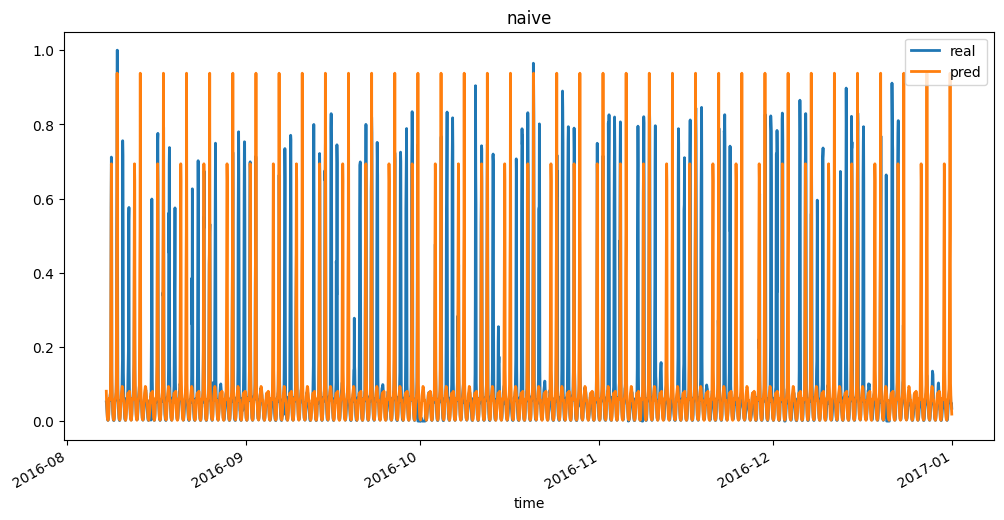

In [ ]:
show_real_previsao(y_test_ts, y_pred_naive, "naive")

In [ ]:
arima.fit(y_train_ts)

ARIMA(p=2, d=0, q=0, seasonal_order=(1, 1, 1, 24), trend=t, random_state=None, add_encoders=None)

In [ ]:
y_pred_arima = arima.predict(len(test))

print(f"MSE: {mse(y_test_ts, y_pred_arima)}")
print(f"RMSE: {rmse(y_test_ts, y_pred_arima)}")

MSE: 0.018904786271727828
RMSE: 0.13749467724871325


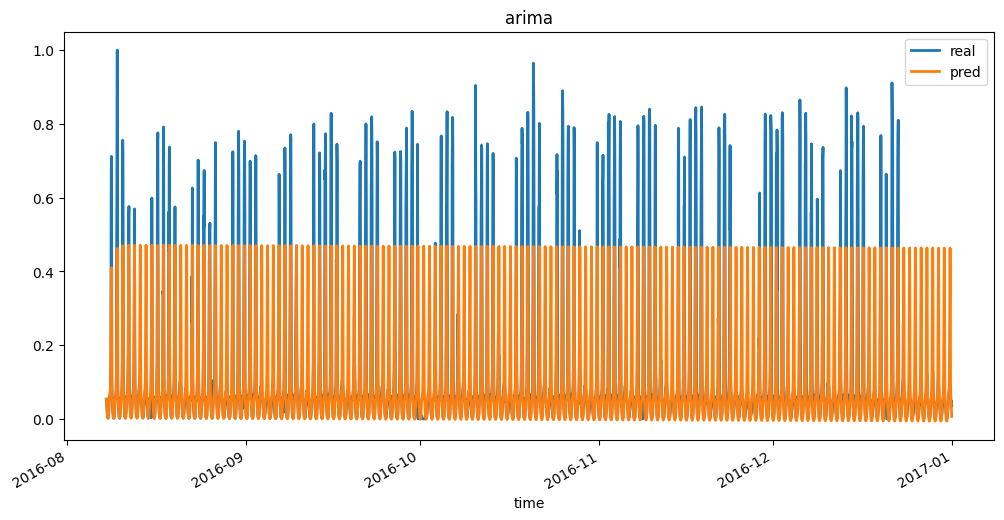

In [ ]:
show_real_previsao(y_test_ts, y_pred_arima, "arima")

In [ ]:
autoArima.fit(train.valor, X=train.drop("valor", axis=1))

AutoARIMA(d=0, random_state=42, start_q=0, suppress_warnings=True)

In [ ]:
y_pred_autoArima = autoArima.predict(fh=test.index, X=test.drop("valor", axis=1))

mse_value = mean_squared_error(
    y_true=test["valor"],
    y_pred=y_pred_autoArima
)

rmse_value = np.sqrt(mse_value)

print(f"MSE: {mse_value}")
print(f"RMSE: {rmse_value}")

MSE: 0.035429979838166724
RMSE: 0.18822853088245342


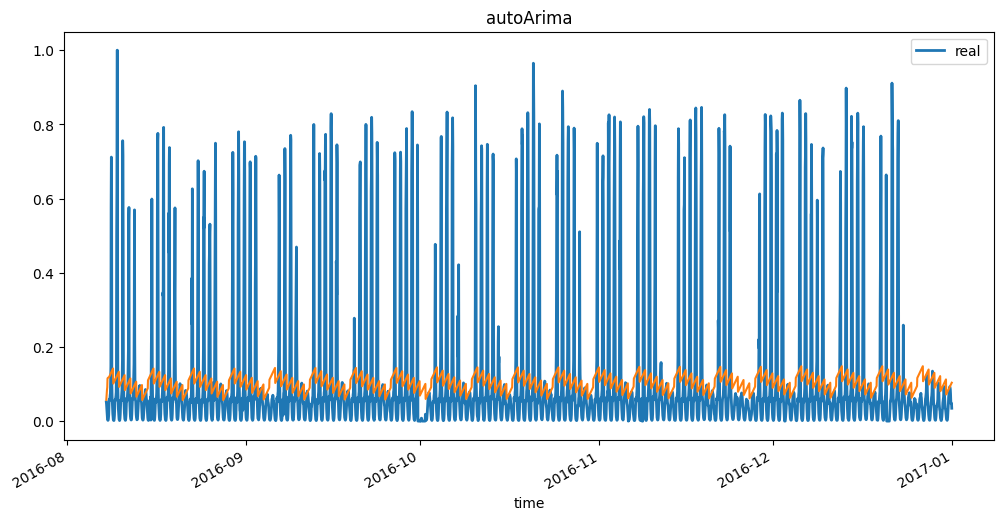

In [ ]:
show_real_previsao(y_test_ts, y_pred_autoArima, "autoArima")

In [ ]:
y_expm1 = y_train_ts.map(lambda x: np.expm1(x))
linear_regression.fit(series=y_expm1, future_covariates=x_train_ts)

SKLearnModel(lags=196, lags_past_covariates=None, lags_future_covariates=[0, 1], output_chunk_length=1, output_chunk_shift=0, add_encoders=None, model=LinearRegression(), multi_models=True, use_static_covariates=True, random_state=None)

In [ ]:
y_pred_lr = linear_regression.predict(len(test)-1, future_covariates=x_test_ts)

print(f"MSE: {mse(y_test_ts, y_pred_lr)}")
print(f"RMSE: {rmse(y_test_ts, y_pred_lr)}")

MSE: 0.01620561250857534
RMSE: 0.1273012667202308


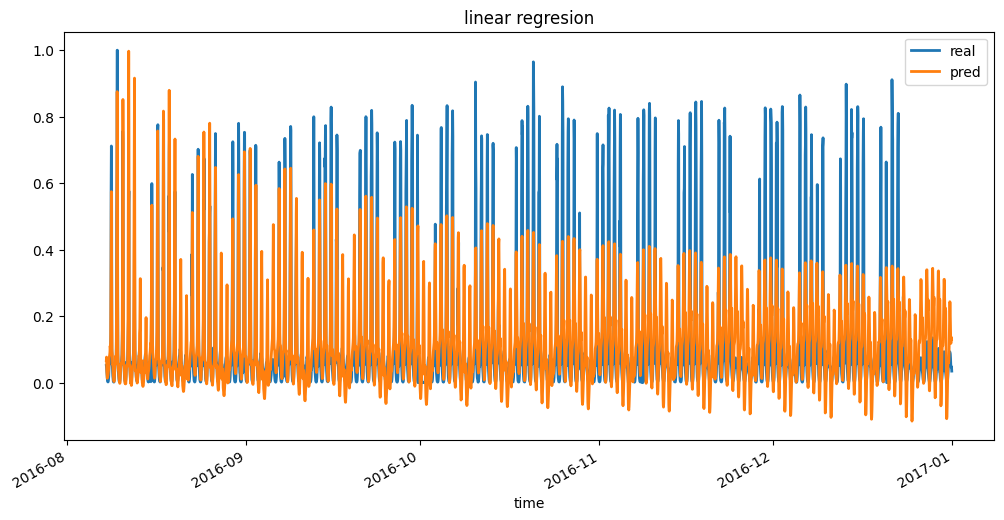

In [ ]:
show_real_previsao(y_test_ts, y_pred_lr, "linear regresion")

In [ ]:
rnnModels.fit(series=y_train_ts, future_covariates=x_train_ts)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.callbacks.model_summary:
  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | rnn             | RNN              | 800    | train
6 | V               | Linear           | 26     | train
-------------------------------------------------------------
826       Trainable params
0         Non-trainable params
826       Total params
0.003     Total estimated model params size (MB)
7         

Training: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


RNNModel(model=RNN, hidden_dim=25, n_rnn_layers=1, dropout=0.3, training_length=168, input_chunk_length=168, batch_size=64, n_epochs=100)

In [ ]:
x_all_ts = x_train_ts.append(x_test_ts)

y_pred_rnn = rnnModels.predict(len(test), future_covariates=x_all_ts)
y_pred_rnn = y_pred_rnn.map(lambda x: x**2)
print(f"MSE: {mse(y_test_ts, y_pred_rnn)}")
print(f"RMSE: {rmse(y_test_ts, y_pred_rnn)}")

INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs


Predicting: |          | 0/? [00:00<?, ?it/s]

MSE: 0.020223411674972356
RMSE: 0.14220904217022332


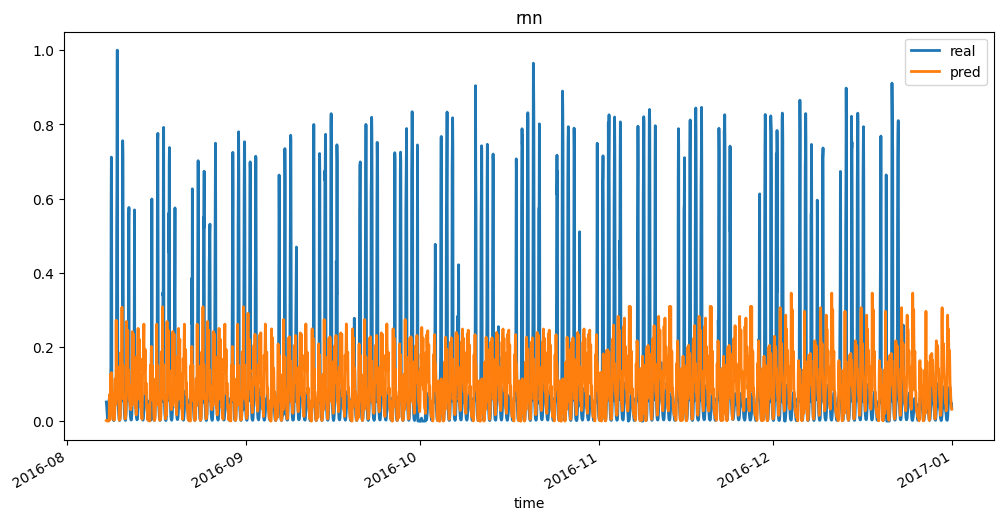

In [ ]:
show_real_previsao(y_test_ts, y_pred_rnn, "rnn")